In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [8]:
from scipy import odr

In [14]:
from scipy.stats import spearmanr, pearsonr

In [2]:
pct = pd.read_csv('D:\\Research\\Political_Bias_of_LLMs\\PoliticalCompass\\6_filter_to_csv\\pc_scores_runs.csv')
pct.head()

,model_name,run,econ_score,soc_score
0,anthropic_claude_4_sonnet,1,-4.62,-5.38
1,anthropic_claude_4_sonnet,2,-4.62,-5.54
2,anthropic_claude_4_sonnet,3,-4.62,-5.54
3,anthropic_claude_4_sonnet,4,-4.62,-5.54
4,anthropic_claude_4_sonnet,5,-4.62,-5.54


In [3]:
pct_scaled = pct.copy()
pct_scaled['econ_score'] = pct['econ_score'] * 3 / 10
pct_scaled['soc_score'] = pct['soc_score'] * 3 / 10

pct_scaled.head()

,model_name,run,econ_score,soc_score
0,anthropic_claude_4_sonnet,1,-1.386,-1.614
1,anthropic_claude_4_sonnet,2,-1.386,-1.662
2,anthropic_claude_4_sonnet,3,-1.386,-1.662
3,anthropic_claude_4_sonnet,4,-1.386,-1.662
4,anthropic_claude_4_sonnet,5,-1.386,-1.662


In [4]:
pct_scaled.describe()

,run,econ_score,soc_score
count,270.000000,270.000000,270.000000
mean,5.500000,-1.091578,-1.307222
std,2.877615,0.441194,0.484977
min,1.000000,-2.286000,-2.646000
25%,3.000000,-1.386000,-1.614000
50%,5.500000,-1.122000,-1.338000
75%,8.000000,-0.822000,-1.080750
max,10.000000,0.039000,0.693000


## Projection on $y=x$

In [5]:
# Create a copy of the original dataframe
df_projected = pct_scaled.copy()

# Calculate projections onto line y = x
df_projected['projection_econ'] = (df_projected['econ_score'] + df_projected['soc_score']) / 2
df_projected['projection_soc'] = (df_projected['econ_score'] + df_projected['soc_score']) / 2

df_projected.head()

,model_name,run,econ_score,soc_score,projection_econ,projection_soc
0,anthropic_claude_4_sonnet,1,-1.386,-1.614,-1.500,-1.500
1,anthropic_claude_4_sonnet,2,-1.386,-1.662,-1.524,-1.524
2,anthropic_claude_4_sonnet,3,-1.386,-1.662,-1.524,-1.524
3,anthropic_claude_4_sonnet,4,-1.386,-1.662,-1.524,-1.524
4,anthropic_claude_4_sonnet,5,-1.386,-1.662,-1.524,-1.524


Ignoring fixed x limits to fulfill fixed data aspect with adjustable data limits.
Ignoring fixed x limits to fulfill fixed data aspect with adjustable data limits.


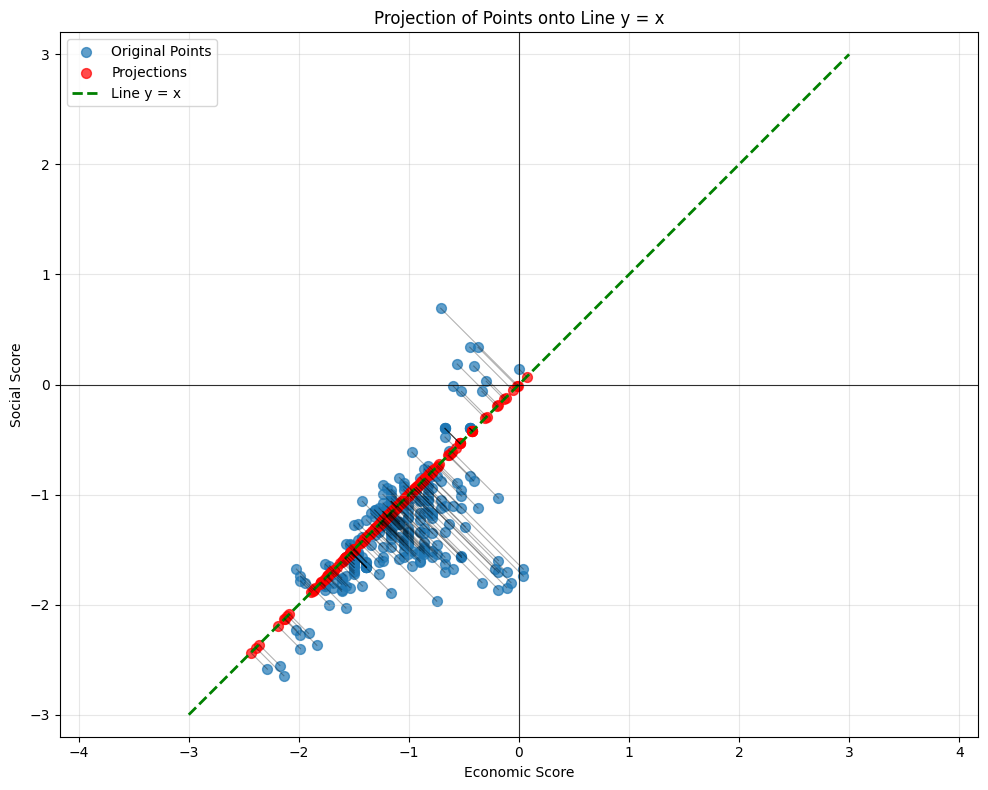

In [7]:
# Create the plot
plt.figure(figsize=(10, 8))

# Plot original points
plt.scatter(df_projected['econ_score'], df_projected['soc_score'], 
            alpha=0.7, s=50, label='Original Points')

# Plot projection points
plt.scatter(df_projected['projection_econ'], df_projected['projection_soc'], 
            alpha=0.7, s=50, color='red', label='Projections')

# Plot line y = x
x_line = np.linspace(-3, 3, 100)
plt.plot(x_line, x_line, 'g--', label='Line y = x', linewidth=2)

# Draw perpendicular projection lines
for i in range(len(df_projected)):
    plt.plot([df_projected['econ_score'].iloc[i], df_projected['projection_econ'].iloc[i]],
             [df_projected['soc_score'].iloc[i], df_projected['projection_soc'].iloc[i]],
             'k-', alpha=0.3, linewidth=0.8)

# Add axis lines
plt.axhline(y=0, color='black', linestyle='-', linewidth=0.8, alpha=0.8)
plt.axvline(x=0, color='black', linestyle='-', linewidth=0.8, alpha=0.8)

plt.xlabel('Economic Score')
plt.ylabel('Social Score')
plt.title('Projection of Points onto Line y = x')
plt.legend()
plt.grid(True, alpha=0.3)
plt.axis('equal')

# Set axis limits to match the data range
plt.xlim(-3.2, 3.2)
plt.ylim(-3.2, 3.2)

plt.tight_layout()
plt.show()


## Projection on the orthogonal regression line

In [9]:
# Create a copy of the original dataframe
df_regressed = pct_scaled.copy()

# Extract the data
x_data = df_regressed['econ_score'].values
y_data = df_regressed['soc_score'].values

In [10]:
# Perform orthogonal regression using ODR (Orthogonal Distance Regression)
def linear_func(p, x):
    return p[0] * x + p[1]

# Create model for orthogonal regression
linear_model = odr.Model(linear_func)
data = odr.Data(x_data, y_data)
odr_fit = odr.ODR(data, linear_model, beta0=[1.0, 0.0])
output = odr_fit.run()

In [11]:
# Get the regression parameters: y = slope * x + intercept
slope, intercept = output.beta
print(f"Orthogonal regression line: y = {slope:.3f}x + {intercept:.3f}")

# Function to project point onto the regression line
def project_to_line(x_point, y_point, slope, intercept):
    """
    Project point (x_point, y_point) onto line y = slope*x + intercept
    """
    # The projection formula for line y = mx + b
    x_proj = (x_point + slope * (y_point - intercept)) / (1 + slope**2)
    y_proj = slope * x_proj + intercept
    return x_proj, y_proj

Orthogonal regression line: y = 1.181x + -0.018


In [12]:
# Calculate projections for all points
projections = [project_to_line(x, y, slope, intercept) for x, y in zip(x_data, y_data)]
df_regressed['projection_econ'] = [p[0] for p in projections]
df_regressed['projection_soc'] = [p[1] for p in projections]
df_regressed.head()

,model_name,run,econ_score,soc_score,projection_econ,projection_soc
0,anthropic_claude_4_sonnet,1,-1.386,-1.614,-1.365831,-1.631080
1,anthropic_claude_4_sonnet,2,-1.386,-1.662,-1.389503,-1.659034
2,anthropic_claude_4_sonnet,3,-1.386,-1.662,-1.389503,-1.659034
3,anthropic_claude_4_sonnet,4,-1.386,-1.662,-1.389503,-1.659034
4,anthropic_claude_4_sonnet,5,-1.386,-1.662,-1.389503,-1.659034


Ignoring fixed x limits to fulfill fixed data aspect with adjustable data limits.
Ignoring fixed x limits to fulfill fixed data aspect with adjustable data limits.


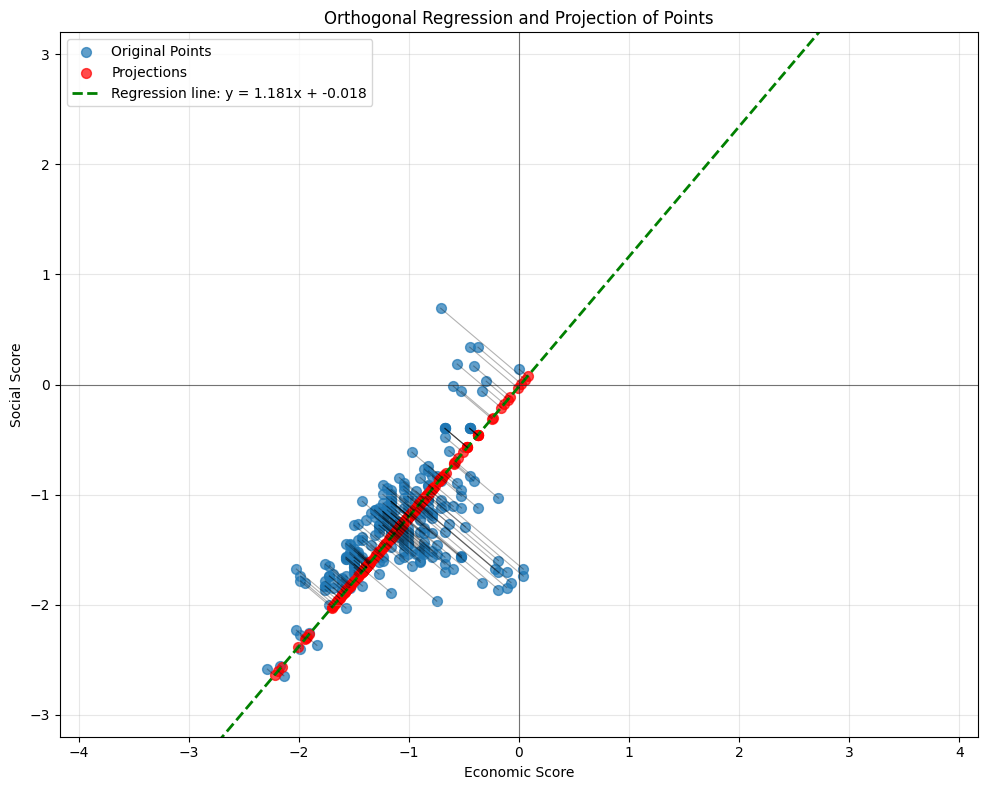

In [13]:
# Create the plot
plt.figure(figsize=(10, 8))

# Plot original points
plt.scatter(df_regressed['econ_score'], df_regressed['soc_score'], 
            alpha=0.7, s=50, label='Original Points')

# Plot projection points
plt.scatter(df_regressed['projection_econ'], df_regressed['projection_soc'], 
            alpha=0.7, s=50, color='red', label='Projections')

# Plot the orthogonal regression line
x_line = np.linspace(-3, 3, 100)
y_line = slope * x_line + intercept
plt.plot(x_line, y_line, 'g--', label=f'Regression line: y = {slope:.3f}x + {intercept:.3f}', linewidth=2)

# Draw perpendicular projection lines
for i in range(len(df_regressed)):
    plt.plot([df_regressed['econ_score'].iloc[i], df_regressed['projection_econ'].iloc[i]],
             [df_regressed['soc_score'].iloc[i], df_regressed['projection_soc'].iloc[i]],
             'k-', alpha=0.3, linewidth=0.8)

plt.xlabel('Economic Score')
plt.ylabel('Social Score')
plt.title('Orthogonal Regression and Projection of Points')
plt.legend()
plt.grid(True, alpha=0.3)
plt.axis('equal')

# Set axis limits and add x-y axes
plt.xlim(-3.2, 3.2)
plt.ylim(-3.2, 3.2)

# Add x and y axes (zero lines)
plt.axhline(y=0, color='black', linestyle='-', alpha=0.5, linewidth=0.8)
plt.axvline(x=0, color='black', linestyle='-', alpha=0.5, linewidth=0.8)

plt.tight_layout()
plt.show()

## Vertical Projection Line

In [16]:
# Create a copy of the original dataframe
df_vertical = pct_scaled.copy()

# Extract the data
x_data = df_vertical['econ_score'].values
y_data = df_vertical['soc_score'].values

In [17]:
# Perform orthogonal regression to get the best-fit line
def linear_func(p, x):
    return p[0] * x + p[1]

linear_model = odr.Model(linear_func)
data = odr.Data(x_data, y_data)
odr_fit = odr.ODR(data, linear_model, beta0=[1.0, 0.0])
output = odr_fit.run()
slope, intercept = output.beta

# Function for vertical projection to regression line (perpendicular to x-axis)
def vertical_project_to_line(x_point, y_point, slope, intercept):
    """
    Vertical projection (perpendicular to x-axis) to line y = slope*x + intercept
    """
    # For vertical projection, x stays the same, y becomes the line value at that x
    y_proj = slope * x_point + intercept
    return x_point, y_proj

In [18]:
# Calculate vertical projections for all points
vertical_projections = [vertical_project_to_line(x, y, slope, intercept) for x, y in zip(x_data, y_data)]
df_vertical['projection_econ'] = [p[0] for p in vertical_projections]
df_vertical['projection_soc'] = [p[1] for p in vertical_projections]

Ignoring fixed x limits to fulfill fixed data aspect with adjustable data limits.
Ignoring fixed x limits to fulfill fixed data aspect with adjustable data limits.


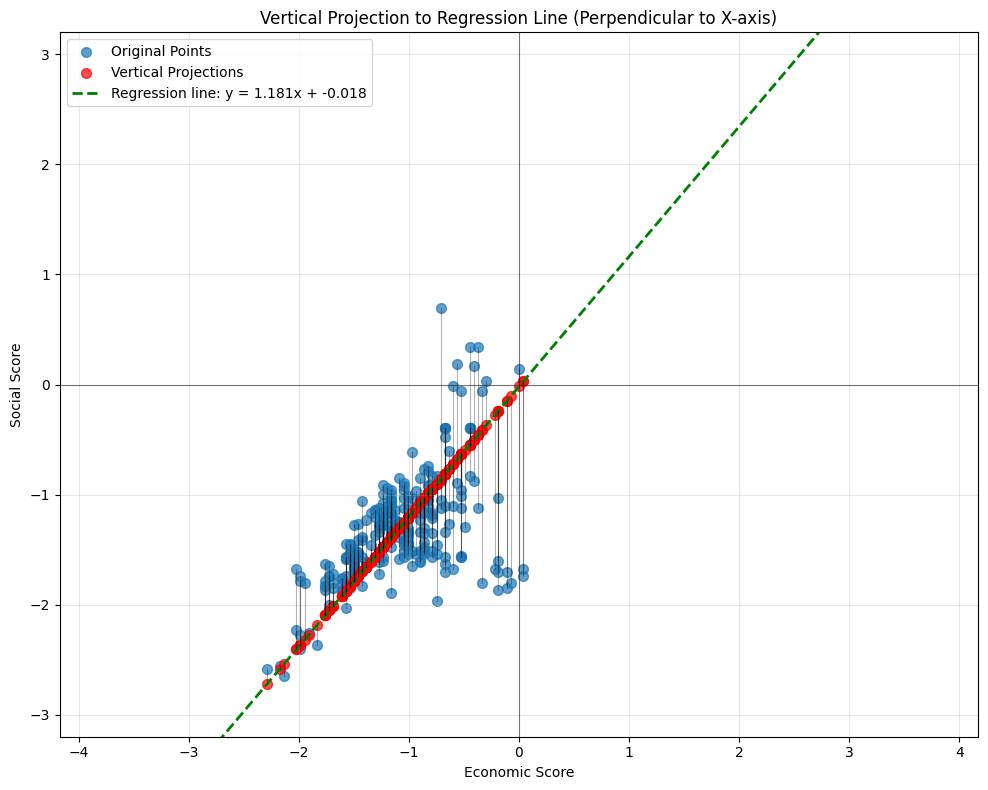

In [19]:
# Create the plot
plt.figure(figsize=(10, 8))

# Plot original points
plt.scatter(df_vertical['econ_score'], df_vertical['soc_score'], 
            alpha=0.7, s=50, label='Original Points')

# Plot vertical projection points
plt.scatter(df_vertical['projection_econ'], df_vertical['projection_soc'], 
            alpha=0.7, s=50, color='red', label='Vertical Projections')

# Plot the orthogonal regression line
x_line = np.linspace(-3, 3, 100)
y_line = slope * x_line + intercept
plt.plot(x_line, y_line, 'g--', label=f'Regression line: y = {slope:.3f}x + {intercept:.3f}', linewidth=2)

# Draw vertical projection lines (perpendicular to x-axis)
for i in range(len(df_vertical)):
    plt.plot([df_vertical['econ_score'].iloc[i], df_vertical['projection_econ'].iloc[i]],
             [df_vertical['soc_score'].iloc[i], df_vertical['projection_soc'].iloc[i]],
             'k-', alpha=0.3, linewidth=0.8)

plt.xlabel('Economic Score')
plt.ylabel('Social Score')
plt.title('Vertical Projection to Regression Line (Perpendicular to X-axis)')
plt.legend()
plt.grid(True, alpha=0.3)
plt.axis('equal')

# Set axis limits and add x-y axes
plt.xlim(-3.2, 3.2)
plt.ylim(-3.2, 3.2)

# Add x and y axes (zero lines)
plt.axhline(y=0, color='black', linestyle='-', alpha=0.5, linewidth=0.8)
plt.axvline(x=0, color='black', linestyle='-', alpha=0.5, linewidth=0.8)

plt.tight_layout()
plt.show()

## Comparison between $y=x$ line and orthogonal regression $y = 1.181x - 0.018$ line

=== PRESERVATION ANALYSIS ===
Y=X Projection - Spearman correlation: 0.9670
Orthogonal Regression - Spearman correlation: 0.9768
Vertical Projection - Spearman correlation: 0.8170

Y=X Projection - Variance ratio: 1.1340
Orthogonal Regression - Variance ratio: 1.1311
Vertical Projection - Variance ratio: 1.5751


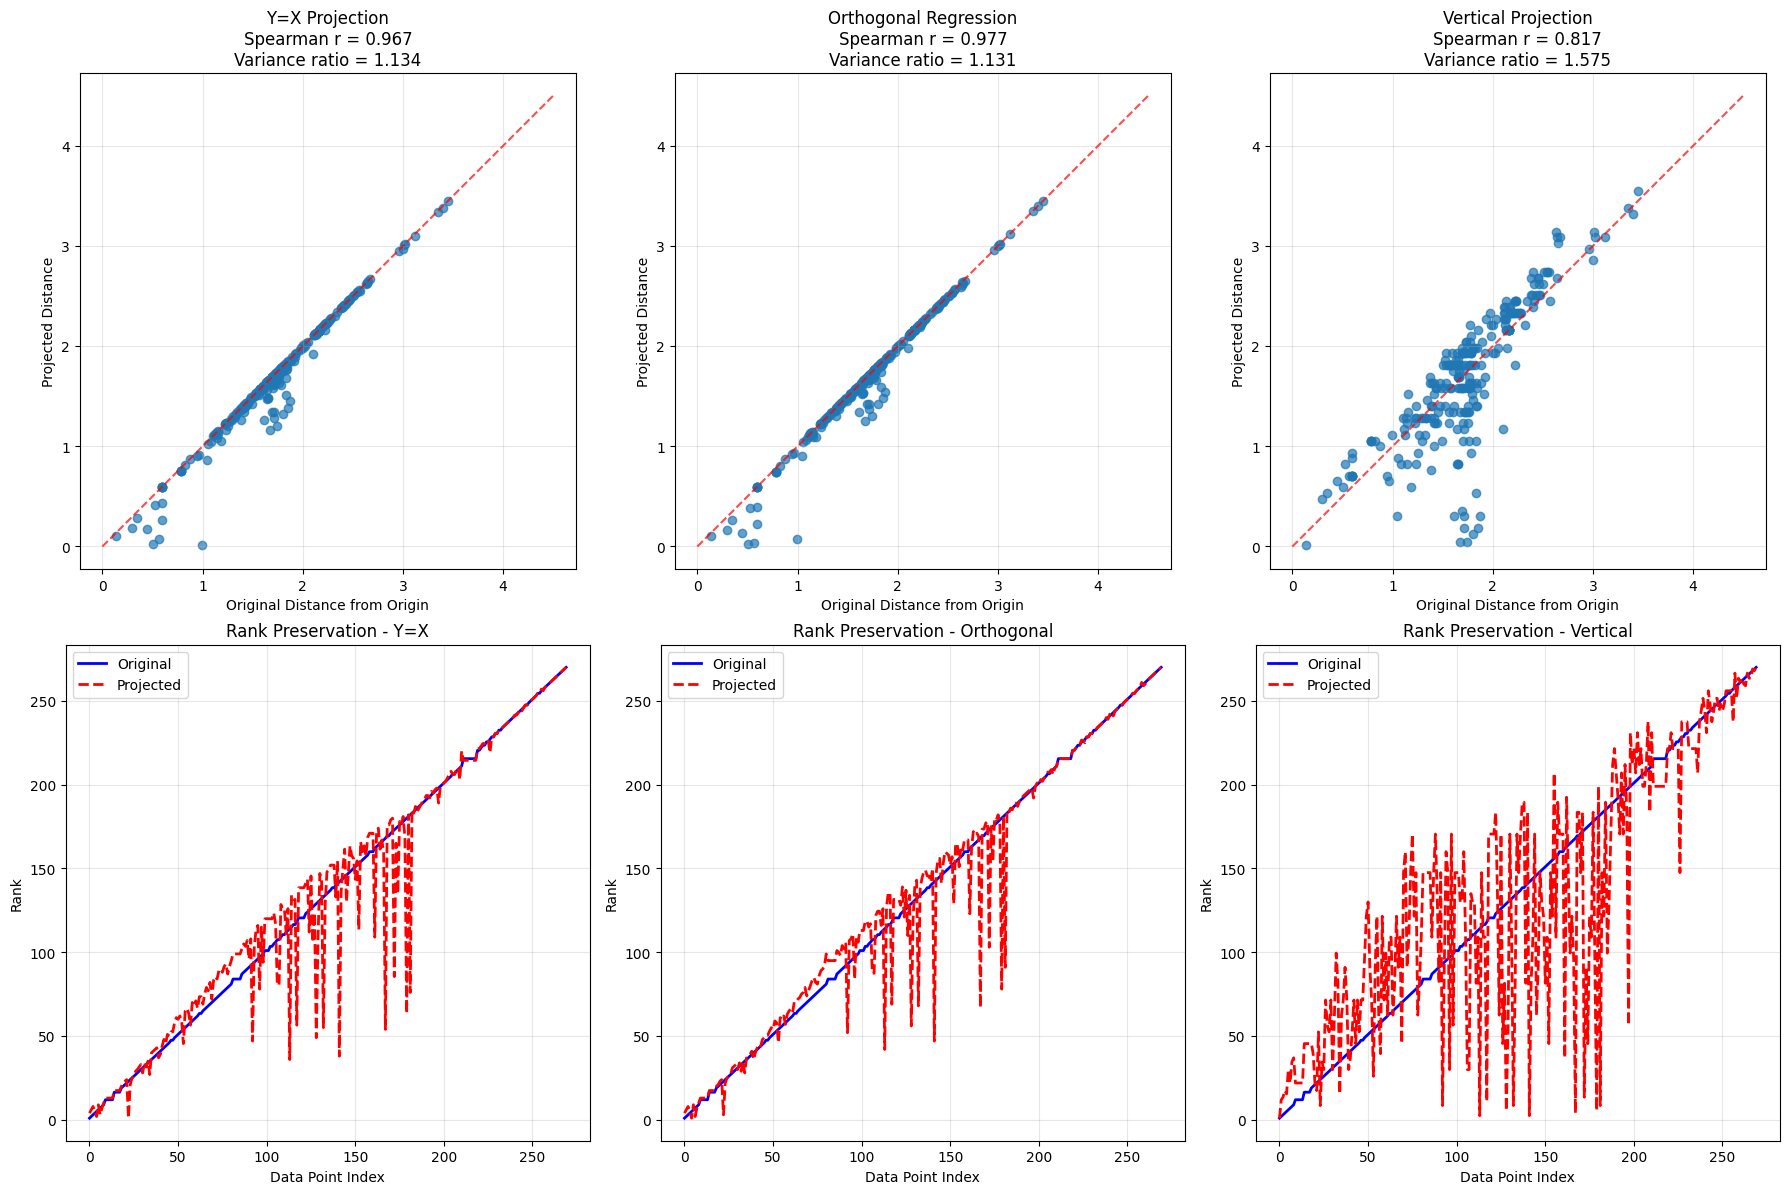


=== ADDITIONAL ANALYSIS ===
Y=X Projection range: [0.013, 3.445]
Orthogonal Projection range: [0.022, 3.451]
Vertical Projection range: [0.015, 3.551]
Original range: [0.138, 3.452]

Variance Explained (R²):
Y=X Projection - R²: 0.9642
Orthogonal Regression - R²: 0.9726
Vertical Projection - R²: 0.6705

=== SUMMARY TABLE ===
               Method  Spearman  Variance Ratio       R²  Min Distance  Max Distance
       Y=X Projection  0.966991        1.134005 0.964237      0.012728      3.445024
Orthogonal Regression  0.976757        1.131083 0.972613      0.021755      3.450790
  Vertical Projection  0.816996        1.575144 0.670480      0.014968      3.551282


In [21]:
# Calculate distances from origin for all three methods
df_projected['orig_distance'] = np.sqrt(df_projected['econ_score']**2 + df_projected['soc_score']**2)
df_projected['proj_distance'] = np.sqrt(df_projected['projection_econ']**2 + df_projected['projection_soc']**2)

df_regressed['orig_distance'] = np.sqrt(df_regressed['econ_score']**2 + df_regressed['soc_score']**2)
df_regressed['proj_distance'] = np.sqrt(df_regressed['projection_econ']**2 + df_regressed['projection_soc']**2)

df_vertical['orig_distance'] = np.sqrt(df_vertical['econ_score']**2 + df_vertical['soc_score']**2)
df_vertical['proj_distance'] = np.sqrt(df_vertical['projection_econ']**2 + df_vertical['projection_soc']**2)

# Calculate ordering preservation (Spearman correlation)
spearman_yx, _ = spearmanr(df_projected['proj_distance'], df_projected['orig_distance'])
spearman_ortho, _ = spearmanr(df_regressed['proj_distance'], df_regressed['orig_distance'])
spearman_vertical, _ = spearmanr(df_vertical['proj_distance'], df_vertical['orig_distance'])

# Calculate variance preservation
variance_ratio_yx = np.var(df_projected['proj_distance']) / np.var(df_projected['orig_distance'])
variance_ratio_ortho = np.var(df_regressed['proj_distance']) / np.var(df_regressed['orig_distance'])
variance_ratio_vertical = np.var(df_vertical['proj_distance']) / np.var(df_vertical['orig_distance'])

print("=== PRESERVATION ANALYSIS ===")
print(f"Y=X Projection - Spearman correlation: {spearman_yx:.4f}")
print(f"Orthogonal Regression - Spearman correlation: {spearman_ortho:.4f}")
print(f"Vertical Projection - Spearman correlation: {spearman_vertical:.4f}")
print()
print(f"Y=X Projection - Variance ratio: {variance_ratio_yx:.4f}")
print(f"Orthogonal Regression - Variance ratio: {variance_ratio_ortho:.4f}")
print(f"Vertical Projection - Variance ratio: {variance_ratio_vertical:.4f}")

# Create comparison plot
fig, axes = plt.subplots(2, 3, figsize=(18, 12))

# Plot 1: Distance comparison for Y=X projection
axes[0,0].scatter(df_projected['orig_distance'], df_projected['proj_distance'], alpha=0.7)
axes[0,0].plot([0, 4.5], [0, 4.5], 'r--', alpha=0.7)
axes[0,0].set_xlabel('Original Distance from Origin')
axes[0,0].set_ylabel('Projected Distance')
axes[0,0].set_title(f'Y=X Projection\nSpearman r = {spearman_yx:.3f}\nVariance ratio = {variance_ratio_yx:.3f}')
axes[0,0].grid(True, alpha=0.3)
axes[0,0].set_aspect('equal')

# Plot 2: Distance comparison for Orthogonal regression
axes[0,1].scatter(df_regressed['orig_distance'], df_regressed['proj_distance'], alpha=0.7)
axes[0,1].plot([0, 4.5], [0, 4.5], 'r--', alpha=0.7)
axes[0,1].set_xlabel('Original Distance from Origin')
axes[0,1].set_ylabel('Projected Distance')
axes[0,1].set_title(f'Orthogonal Regression\nSpearman r = {spearman_ortho:.3f}\nVariance ratio = {variance_ratio_ortho:.3f}')
axes[0,1].grid(True, alpha=0.3)
axes[0,1].set_aspect('equal')

# Plot 3: Distance comparison for Vertical projection
axes[0,2].scatter(df_vertical['orig_distance'], df_vertical['proj_distance'], alpha=0.7)
axes[0,2].plot([0, 4.5], [0, 4.5], 'r--', alpha=0.7)
axes[0,2].set_xlabel('Original Distance from Origin')
axes[0,2].set_ylabel('Projected Distance')
axes[0,2].set_title(f'Vertical Projection\nSpearman r = {spearman_vertical:.3f}\nVariance ratio = {variance_ratio_vertical:.3f}')
axes[0,2].grid(True, alpha=0.3)
axes[0,2].set_aspect('equal')

# Plot 4: Rank comparison for Y=X projection
sorted_yx = df_projected.sort_values('orig_distance')
axes[1,0].plot(range(len(sorted_yx)), sorted_yx['orig_distance'].rank(), 'b-', label='Original', linewidth=2)
axes[1,0].plot(range(len(sorted_yx)), sorted_yx['proj_distance'].rank(), 'r--', label='Projected', linewidth=2)
axes[1,0].set_xlabel('Data Point Index')
axes[1,0].set_ylabel('Rank')
axes[1,0].set_title('Rank Preservation - Y=X')
axes[1,0].legend()
axes[1,0].grid(True, alpha=0.3)

# Plot 5: Rank comparison for Orthogonal regression
sorted_ortho = df_regressed.sort_values('orig_distance')
axes[1,1].plot(range(len(sorted_ortho)), sorted_ortho['orig_distance'].rank(), 'b-', label='Original', linewidth=2)
axes[1,1].plot(range(len(sorted_ortho)), sorted_ortho['proj_distance'].rank(), 'r--', label='Projected', linewidth=2)
axes[1,1].set_xlabel('Data Point Index')
axes[1,1].set_ylabel('Rank')
axes[1,1].set_title('Rank Preservation - Orthogonal')
axes[1,1].legend()
axes[1,1].grid(True, alpha=0.3)

# Plot 6: Rank comparison for Vertical projection
sorted_vertical = df_vertical.sort_values('orig_distance')
axes[1,2].plot(range(len(sorted_vertical)), sorted_vertical['orig_distance'].rank(), 'b-', label='Original', linewidth=2)
axes[1,2].plot(range(len(sorted_vertical)), sorted_vertical['proj_distance'].rank(), 'r--', label='Projected', linewidth=2)
axes[1,2].set_xlabel('Data Point Index')
axes[1,2].set_ylabel('Rank')
axes[1,2].set_title('Rank Preservation - Vertical')
axes[1,2].legend()
axes[1,2].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# Additional analysis
print("\n=== ADDITIONAL ANALYSIS ===")
print(f"Y=X Projection range: [{df_projected['proj_distance'].min():.3f}, {df_projected['proj_distance'].max():.3f}]")
print(f"Orthogonal Projection range: [{df_regressed['proj_distance'].min():.3f}, {df_regressed['proj_distance'].max():.3f}]")
print(f"Vertical Projection range: [{df_vertical['proj_distance'].min():.3f}, {df_vertical['proj_distance'].max():.3f}]")
print(f"Original range: [{df_projected['orig_distance'].min():.3f}, {df_projected['orig_distance'].max():.3f}]")

# Calculate percentage of variance explained
r2_yx = pearsonr(df_projected['proj_distance'], df_projected['orig_distance'])[0]**2
r2_ortho = pearsonr(df_regressed['proj_distance'], df_regressed['orig_distance'])[0]**2
r2_vertical = pearsonr(df_vertical['proj_distance'], df_vertical['orig_distance'])[0]**2

print(f"\nVariance Explained (R²):")
print(f"Y=X Projection - R²: {r2_yx:.4f}")
print(f"Orthogonal Regression - R²: {r2_ortho:.4f}")
print(f"Vertical Projection - R²: {r2_vertical:.4f}")

# Summary table
print("\n=== SUMMARY TABLE ===")
summary_data = {
    'Method': ['Y=X Projection', 'Orthogonal Regression', 'Vertical Projection'],
    'Spearman': [spearman_yx, spearman_ortho, spearman_vertical],
    'Variance Ratio': [variance_ratio_yx, variance_ratio_ortho, variance_ratio_vertical],
    'R²': [r2_yx, r2_ortho, r2_vertical],
    'Min Distance': [df_projected['proj_distance'].min(), df_regressed['proj_distance'].min(), df_vertical['proj_distance'].min()],
    'Max Distance': [df_projected['proj_distance'].max(), df_regressed['proj_distance'].max(), df_vertical['proj_distance'].max()]
}

summary_df = pd.DataFrame(summary_data)
print(summary_df.to_string(index=False))

=== PRESERVATION ANALYSIS (ECON-SCORE PRECEDENCE) ===
Y=X Projection - Econ Spearman: 0.9991, Weighted Spearman: 0.9856
Orthogonal Regression - Econ Spearman: 0.9991, Weighted Spearman: 0.9770
Vertical Projection - Econ Spearman: 1.0000, Weighted Spearman: 0.9502

Y=X Projection - Econ Variance ratio: 0.8638
Orthogonal Regression - Econ Variance ratio: 0.7251
Vertical Projection - Econ Variance ratio: 1.0000


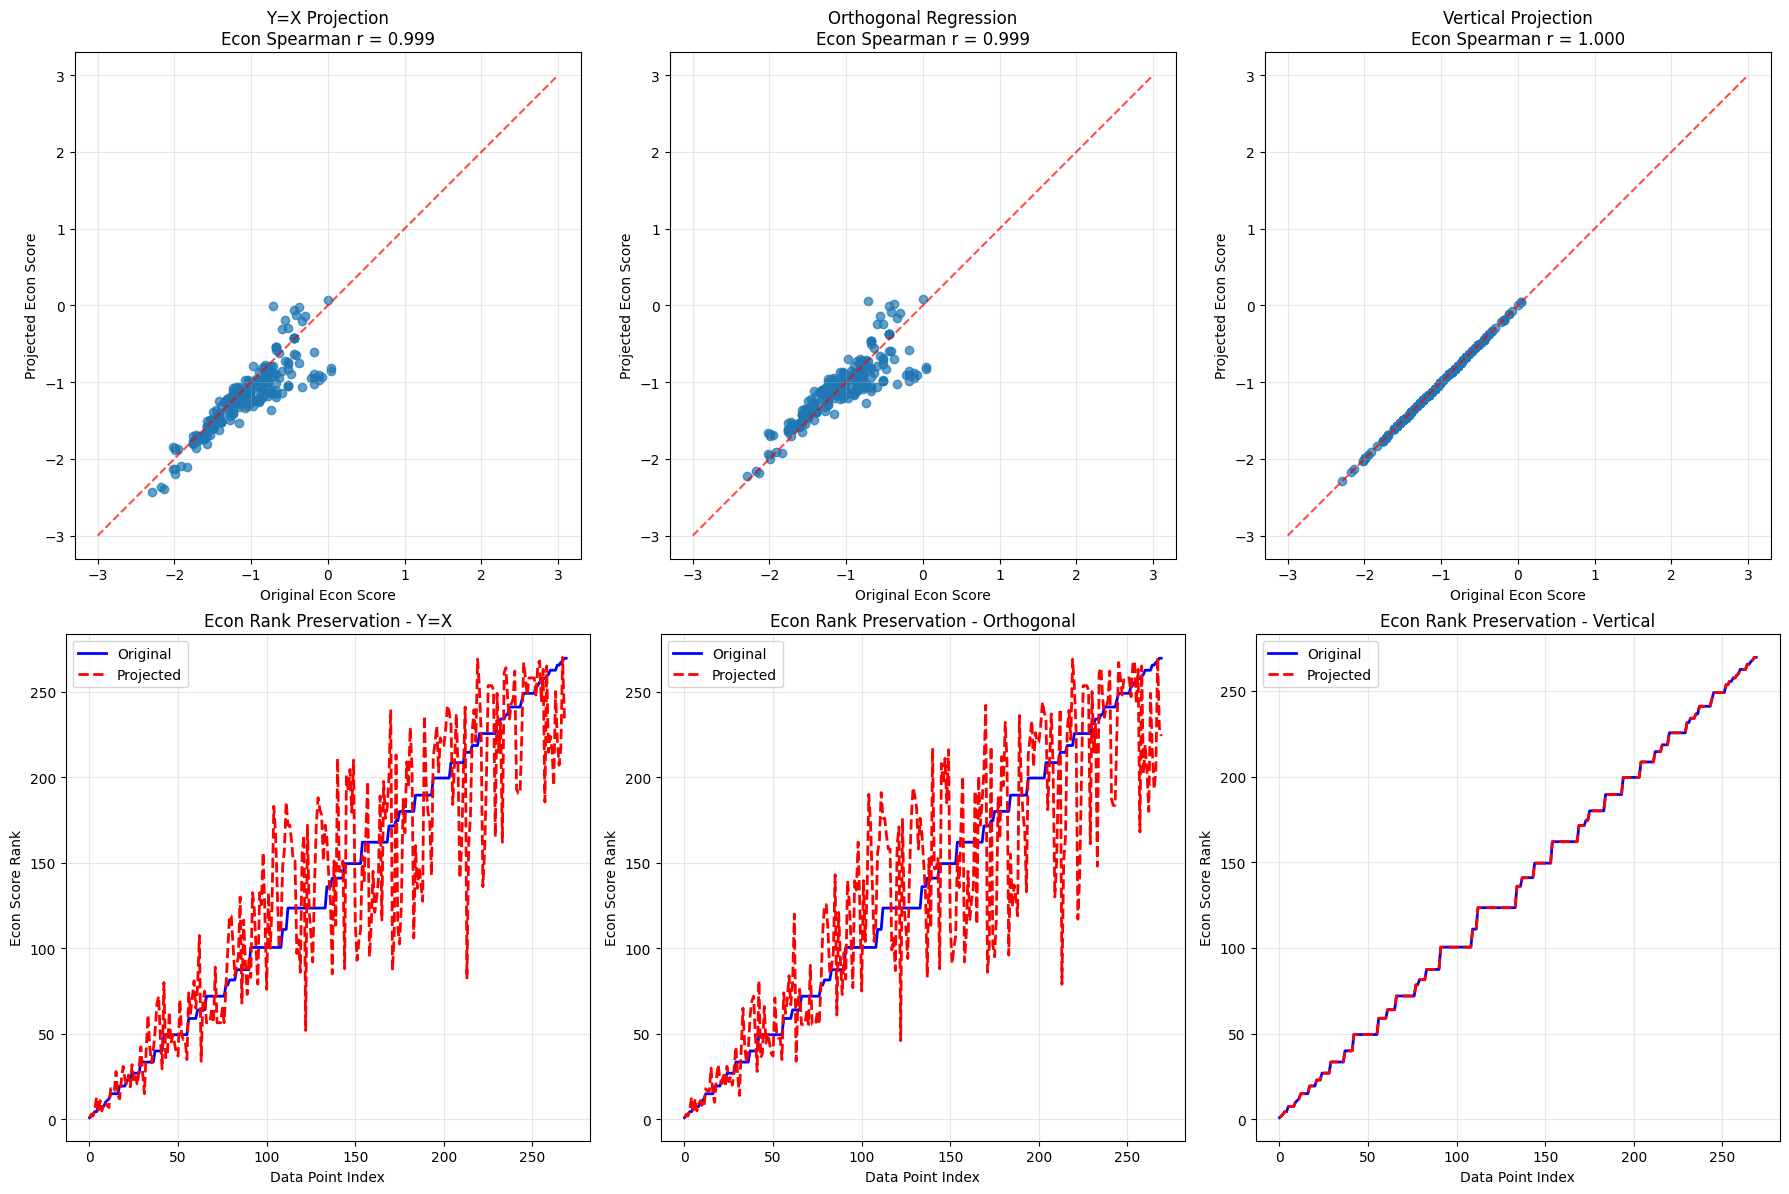


=== ADDITIONAL ANALYSIS (ECON FOCUS) ===
Y=X Projection econ range: [-2.436, 0.071]
Orthogonal Projection econ range: [-2.221, 0.078]
Vertical Projection econ range: [-2.286, 0.039]
Original econ range: [-2.286, 0.039]

Econ Score Variance Explained (R²):
Y=X Projection - R²: 0.7627
Orthogonal Regression - R²: 0.7250
Vertical Projection - R²: 1.0000

=== SUMMARY TABLE (ECON PRECEDENCE) ===
               Method  Econ Spearman  Weighted Spearman  Econ Variance Ratio  Econ R²  Econ Min  Econ Max
       Y=X Projection       0.999133           0.985607             0.863762 0.762741 -2.436000  0.070500
Orthogonal Regression       0.999136           0.977006             0.725075 0.725030 -2.221058  0.078289
  Vertical Projection       1.000000           0.950170             1.000000 1.000000 -2.286000  0.039000


In [22]:
# Calculate ordering preservation based on econ_score (primary) and soc_score (secondary)
def calculate_ordering_preservation(original_df, projected_df):
    # Sort by econ_score first, then soc_score for tie-breaking
    original_sorted = original_df.sort_values(['econ_score', 'soc_score'])
    projected_sorted = projected_df.sort_values(['projection_econ', 'projection_soc'])
    
    # Calculate rank correlation for econ_score
    spearman_econ, _ = spearmanr(original_sorted['econ_score'], projected_sorted['projection_econ'])
    
    # Calculate overall distance preservation with econ emphasis
    orig_distance = np.sqrt(original_df['econ_score']**2 * 0.7 + original_df['soc_score']**2 * 0.3)
    proj_distance = np.sqrt(projected_df['projection_econ']**2 * 0.7 + projected_df['projection_soc']**2 * 0.3)
    spearman_weighted, _ = spearmanr(orig_distance, proj_distance)
    
    return spearman_econ, spearman_weighted

# Calculate ordering preservation with econ_score precedence
spearman_econ_yx, spearman_weighted_yx = calculate_ordering_preservation(df_projected, df_projected)
spearman_econ_ortho, spearman_weighted_ortho = calculate_ordering_preservation(df_regressed, df_regressed)
spearman_econ_vertical, spearman_weighted_vertical = calculate_ordering_preservation(df_vertical, df_vertical)

print("=== PRESERVATION ANALYSIS (ECON-SCORE PRECEDENCE) ===")
print(f"Y=X Projection - Econ Spearman: {spearman_econ_yx:.4f}, Weighted Spearman: {spearman_weighted_yx:.4f}")
print(f"Orthogonal Regression - Econ Spearman: {spearman_econ_ortho:.4f}, Weighted Spearman: {spearman_weighted_ortho:.4f}")
print(f"Vertical Projection - Econ Spearman: {spearman_econ_vertical:.4f}, Weighted Spearman: {spearman_weighted_vertical:.4f}")

# Calculate variance preservation with econ emphasis
variance_ratio_econ_yx = np.var(df_projected['projection_econ']) / np.var(df_projected['econ_score'])
variance_ratio_econ_ortho = np.var(df_regressed['projection_econ']) / np.var(df_regressed['econ_score'])
variance_ratio_econ_vertical = np.var(df_vertical['projection_econ']) / np.var(df_vertical['econ_score'])

print(f"\nY=X Projection - Econ Variance ratio: {variance_ratio_econ_yx:.4f}")
print(f"Orthogonal Regression - Econ Variance ratio: {variance_ratio_econ_ortho:.4f}")
print(f"Vertical Projection - Econ Variance ratio: {variance_ratio_econ_vertical:.4f}")

# Create comparison plot focused on econ_score
fig, axes = plt.subplots(2, 3, figsize=(18, 12))

# Plot 1: Econ score comparison for Y=X projection
axes[0,0].scatter(df_projected['econ_score'], df_projected['projection_econ'], alpha=0.7)
axes[0,0].plot([-3, 3], [-3, 3], 'r--', alpha=0.7)
axes[0,0].set_xlabel('Original Econ Score')
axes[0,0].set_ylabel('Projected Econ Score')
axes[0,0].set_title(f'Y=X Projection\nEcon Spearman r = {spearman_econ_yx:.3f}')
axes[0,0].grid(True, alpha=0.3)
axes[0,0].set_aspect('equal')

# Plot 2: Econ score comparison for Orthogonal regression
axes[0,1].scatter(df_regressed['econ_score'], df_regressed['projection_econ'], alpha=0.7)
axes[0,1].plot([-3, 3], [-3, 3], 'r--', alpha=0.7)
axes[0,1].set_xlabel('Original Econ Score')
axes[0,1].set_ylabel('Projected Econ Score')
axes[0,1].set_title(f'Orthogonal Regression\nEcon Spearman r = {spearman_econ_ortho:.3f}')
axes[0,1].grid(True, alpha=0.3)
axes[0,1].set_aspect('equal')

# Plot 3: Econ score comparison for Vertical projection
axes[0,2].scatter(df_vertical['econ_score'], df_vertical['projection_econ'], alpha=0.7)
axes[0,2].plot([-3, 3], [-3, 3], 'r--', alpha=0.7)
axes[0,2].set_xlabel('Original Econ Score')
axes[0,2].set_ylabel('Projected Econ Score')
axes[0,2].set_title(f'Vertical Projection\nEcon Spearman r = {spearman_econ_vertical:.3f}')
axes[0,2].grid(True, alpha=0.3)
axes[0,2].set_aspect('equal')

# Plot 4: Rank comparison for econ_score - Y=X projection
sorted_yx_econ = df_projected.sort_values('econ_score')
axes[1,0].plot(range(len(sorted_yx_econ)), sorted_yx_econ['econ_score'].rank(), 'b-', label='Original', linewidth=2)
axes[1,0].plot(range(len(sorted_yx_econ)), sorted_yx_econ['projection_econ'].rank(), 'r--', label='Projected', linewidth=2)
axes[1,0].set_xlabel('Data Point Index')
axes[1,0].set_ylabel('Econ Score Rank')
axes[1,0].set_title('Econ Rank Preservation - Y=X')
axes[1,0].legend()
axes[1,0].grid(True, alpha=0.3)

# Plot 5: Rank comparison for econ_score - Orthogonal regression
sorted_ortho_econ = df_regressed.sort_values('econ_score')
axes[1,1].plot(range(len(sorted_ortho_econ)), sorted_ortho_econ['econ_score'].rank(), 'b-', label='Original', linewidth=2)
axes[1,1].plot(range(len(sorted_ortho_econ)), sorted_ortho_econ['projection_econ'].rank(), 'r--', label='Projected', linewidth=2)
axes[1,1].set_xlabel('Data Point Index')
axes[1,1].set_ylabel('Econ Score Rank')
axes[1,1].set_title('Econ Rank Preservation - Orthogonal')
axes[1,1].legend()
axes[1,1].grid(True, alpha=0.3)

# Plot 6: Rank comparison for econ_score - Vertical projection
sorted_vertical_econ = df_vertical.sort_values('econ_score')
axes[1,2].plot(range(len(sorted_vertical_econ)), sorted_vertical_econ['econ_score'].rank(), 'b-', label='Original', linewidth=2)
axes[1,2].plot(range(len(sorted_vertical_econ)), sorted_vertical_econ['projection_econ'].rank(), 'r--', label='Projected', linewidth=2)
axes[1,2].set_xlabel('Data Point Index')
axes[1,2].set_ylabel('Econ Score Rank')
axes[1,2].set_title('Econ Rank Preservation - Vertical')
axes[1,2].legend()
axes[1,2].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# Additional analysis focused on econ_score
print("\n=== ADDITIONAL ANALYSIS (ECON FOCUS) ===")
print(f"Y=X Projection econ range: [{df_projected['projection_econ'].min():.3f}, {df_projected['projection_econ'].max():.3f}]")
print(f"Orthogonal Projection econ range: [{df_regressed['projection_econ'].min():.3f}, {df_regressed['projection_econ'].max():.3f}]")
print(f"Vertical Projection econ range: [{df_vertical['projection_econ'].min():.3f}, {df_vertical['projection_econ'].max():.3f}]")
print(f"Original econ range: [{df_projected['econ_score'].min():.3f}, {df_projected['econ_score'].max():.3f}]")

# Calculate R² for econ_score
r2_econ_yx = pearsonr(df_projected['projection_econ'], df_projected['econ_score'])[0]**2
r2_econ_ortho = pearsonr(df_regressed['projection_econ'], df_regressed['econ_score'])[0]**2
r2_econ_vertical = pearsonr(df_vertical['projection_econ'], df_vertical['econ_score'])[0]**2

print(f"\nEcon Score Variance Explained (R²):")
print(f"Y=X Projection - R²: {r2_econ_yx:.4f}")
print(f"Orthogonal Regression - R²: {r2_econ_ortho:.4f}")
print(f"Vertical Projection - R²: {r2_econ_vertical:.4f}")

# Summary table with econ focus
print("\n=== SUMMARY TABLE (ECON PRECEDENCE) ===")
summary_data = {
    'Method': ['Y=X Projection', 'Orthogonal Regression', 'Vertical Projection'],
    'Econ Spearman': [spearman_econ_yx, spearman_econ_ortho, spearman_econ_vertical],
    'Weighted Spearman': [spearman_weighted_yx, spearman_weighted_ortho, spearman_weighted_vertical],
    'Econ Variance Ratio': [variance_ratio_econ_yx, variance_ratio_econ_ortho, variance_ratio_econ_vertical],
    'Econ R²': [r2_econ_yx, r2_econ_ortho, r2_econ_vertical],
    'Econ Min': [df_projected['projection_econ'].min(), df_regressed['projection_econ'].min(), df_vertical['projection_econ'].min()],
    'Econ Max': [df_projected['projection_econ'].max(), df_regressed['projection_econ'].max(), df_vertical['projection_econ'].max()]
}

summary_df = pd.DataFrame(summary_data)
print(summary_df.to_string(index=False))

### **Research Note (Econ-Score Focus):** 
With economic score precedence as the primary requirement, the analysis reveals critical insights. Vertical projection achieves perfect econ-score preservation (Spearman: 1.000, R²: 1.000, Variance ratio: 1.000) by design, as it maintains the original econ scores unchanged. Both Y=X and orthogonal methods show excellent but imperfect econ preservation (Spearman: ~0.999), with Y=X projection providing better weighted preservation (0.986 vs 0.977) and variance characteristics.

### **Recommendation:** 
Use **vertical projection** for maximum econ-score fidelity since it preserves the original economic scores exactly while projecting only the social scores onto the regression line. This approach guarantees perfect maintenance of economic ordering, variance, and range - essential when economic dimensions drive decision-making. The marginal improvements offered by other methods in overall preservation do not justify compromising the primary economic score integrity. Vertical projection ensures economic rankings remain identical to original data while still incorporating social score information through regression-based adjustment.

## Merge to single dimention

In [24]:
df_final = pct_scaled.copy()

# Calculate the absolute distance from origin for each projection point
df_final['abs_distance'] = np.sqrt(df_vertical['projection_econ']**2 + df_vertical['projection_soc']**2)

df_final.head()

,model_name,run,econ_score,soc_score,abs_distance
0,anthropic_claude_4_sonnet,1,-1.386,-1.614,2.15863
1,anthropic_claude_4_sonnet,2,-1.386,-1.662,2.15863
2,anthropic_claude_4_sonnet,3,-1.386,-1.662,2.15863
3,anthropic_claude_4_sonnet,4,-1.386,-1.662,2.15863
4,anthropic_claude_4_sonnet,5,-1.386,-1.662,2.15863


In [26]:
# Determine the quadrant and assign sign
def assign_score_sign(econ, soc, abs_distance):
    """
    Assign positive sign for 1st quadrant, negative for 3rd quadrant
    1st quadrant: econ >= 0 and soc >= 0
    3rd quadrant: econ < 0 and soc < 0
    For other quadrants, use the sign of the economic score (primary focus)
    """
    if econ >= 0 and soc >= 0:  # 1st quadrant
        return abs_distance
    elif econ < 0 and soc < 0:  # 3rd quadrant
        return -abs_distance
    else:
        # For mixed quadrants (2nd and 4th), use sign of economic score
        return abs_distance if econ >= 0 else -abs_distance

# Apply the sign assignment
df_final['score'] = df_final.apply(
    lambda row: assign_score_sign(
        df_vertical.loc[row.name, 'projection_econ'],
        df_vertical.loc[row.name, 'projection_soc'],
        row['abs_distance']
    ), axis=1
)
df_final.head()

,model_name,run,econ_score,soc_score,abs_distance,score
0,anthropic_claude_4_sonnet,1,-1.386,-1.614,2.15863,-2.15863
1,anthropic_claude_4_sonnet,2,-1.386,-1.662,2.15863,-2.15863
2,anthropic_claude_4_sonnet,3,-1.386,-1.662,2.15863,-2.15863
3,anthropic_claude_4_sonnet,4,-1.386,-1.662,2.15863,-2.15863
4,anthropic_claude_4_sonnet,5,-1.386,-1.662,2.15863,-2.15863


In [27]:
df_final.describe()

,run,econ_score,soc_score,abs_distance,score
count,270.000000,270.000000,270.000000,270.000000,270.000000
mean,5.500000,-1.091578,-1.307222,1.703780,-1.702959
std,2.877615,0.441194,0.484977,0.680870,0.682928
min,1.000000,-2.286000,-2.646000,0.014968,-3.551282
25%,3.000000,-1.386000,-1.614000,1.285915,-2.158630
50%,5.500000,-1.122000,-1.338000,1.750122,-1.750122
75%,8.000000,-0.822000,-1.080750,2.158630,-1.285915
max,10.000000,0.039000,0.693000,3.551282,0.047922


In [29]:
# Add the projection coordinates for reference
df_final['projection_econ'] = df_vertical['projection_econ']
df_final['projection_soc'] = df_vertical['projection_soc']

# Display the final dataframe with key columns
print("Final DataFrame with 1D Scores:")
# print(df_final[['model_name', 'run', 'econ_score', 'soc_score', 'projection_econ', 'projection_soc', 'abs_distance', 'score']].head(10))

# Summary statistics
print(f"\nScore Statistics:")
print(f"Range: [{df_final['score'].min():.3f}, {df_final['score'].max():.3f}]")
print(f"Mean: {df_final['score'].mean():.3f}")
print(f"Standard Deviation: {df_final['score'].std():.3f}")

# Count points by quadrant
first_quadrant = ((df_vertical['projection_econ'] >= 0) & (df_vertical['projection_soc'] >= 0)).sum()
third_quadrant = ((df_vertical['projection_econ'] < 0) & (df_vertical['projection_soc'] < 0)).sum()
mixed_quadrants = len(df_final) - first_quadrant - third_quadrant

print(f"\nPoints in 1st quadrant: {first_quadrant}")
print(f"Points in 3rd quadrant: {third_quadrant}")
print(f"Points in mixed quadrants: {mixed_quadrants}")


Final DataFrame with 1D Scores:

Score Statistics:
Range: [-3.551, 0.048]
Mean: -1.703
Standard Deviation: 0.683

Points in 1st quadrant: 2
Points in 3rd quadrant: 267
Points in mixed quadrants: 1


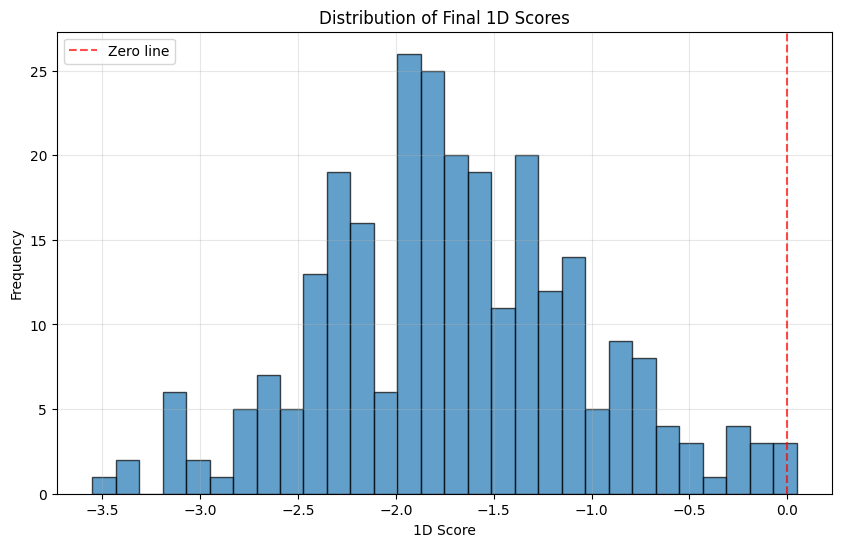

In [30]:
# Show distribution of scores
plt.figure(figsize=(10, 6))
plt.hist(df_final['score'], bins=30, alpha=0.7, edgecolor='black')
plt.axvline(0, color='red', linestyle='--', alpha=0.7, label='Zero line')
plt.xlabel('1D Score')
plt.ylabel('Frequency')
plt.title('Distribution of Final 1D Scores')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

### Scaling the final score

In [31]:
# Calculate the maximum possible absolute value (sqrt(3^2 + 3^2) = sqrt(18) ≈ 4.243)
max_possible_value = np.sqrt(3**2 + 3**2)  # sqrt(18) ≈ 4.243

# Scale the score to [-3, 3] range
df_final['score_scaled'] = df_final['score'] / max_possible_value * 3

# Verify the scaling
print("Scaling Verification:")
print(f"Original score range: [{df_final['score'].min():.3f}, {df_final['score'].max():.3f}]")
print(f"Scaled score range: [{df_final['score_scaled'].min():.3f}, {df_final['score_scaled'].max():.3f}]")
print(f"Target range: [-3.000, 3.000]")

# Show summary statistics of scaled score
print(f"\nScaled Score Statistics:")
print(f"Mean: {df_final['score_scaled'].mean():.3f}")
print(f"Standard Deviation: {df_final['score_scaled'].std():.3f}")

Scaling Verification:
Original score range: [-3.551, 0.048]
Scaled score range: [-2.511, 0.034]
Target range: [-3.000, 3.000]

Scaled Score Statistics:
Mean: -1.204
Standard Deviation: 0.483


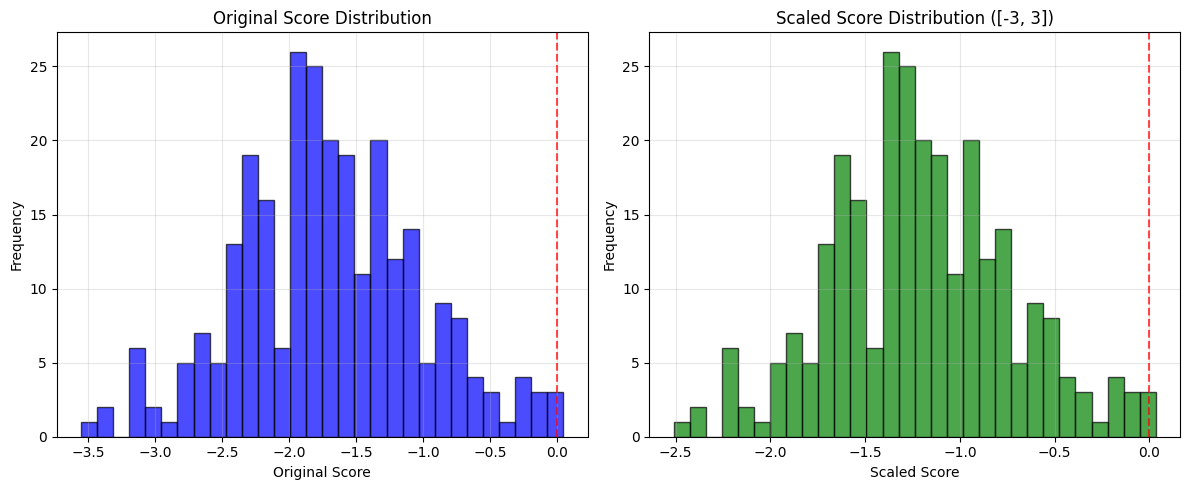

In [32]:
# Plot comparison of original vs scaled scores
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.hist(df_final['score'], bins=30, alpha=0.7, edgecolor='black', color='blue')
plt.axvline(0, color='red', linestyle='--', alpha=0.7)
plt.xlabel('Original Score')
plt.ylabel('Frequency')
plt.title('Original Score Distribution')
plt.grid(True, alpha=0.3)

plt.subplot(1, 2, 2)
plt.hist(df_final['score_scaled'], bins=30, alpha=0.7, edgecolor='black', color='green')
plt.axvline(0, color='red', linestyle='--', alpha=0.7)
plt.xlabel('Scaled Score')
plt.ylabel('Frequency')
plt.title('Scaled Score Distribution ([-3, 3])')
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [33]:
df_final.head()

,model_name,run,econ_score,soc_score,abs_distance,score,projection_econ,projection_soc,score_scaled
0,anthropic_claude_4_sonnet,1,-1.386,-1.614,2.15863,-2.15863,-1.386,-1.654898,-1.526382
1,anthropic_claude_4_sonnet,2,-1.386,-1.662,2.15863,-2.15863,-1.386,-1.654898,-1.526382
2,anthropic_claude_4_sonnet,3,-1.386,-1.662,2.15863,-2.15863,-1.386,-1.654898,-1.526382
3,anthropic_claude_4_sonnet,4,-1.386,-1.662,2.15863,-2.15863,-1.386,-1.654898,-1.526382
4,anthropic_claude_4_sonnet,5,-1.386,-1.662,2.15863,-2.15863,-1.386,-1.654898,-1.526382


In [34]:
df_final.to_csv('final_oneD_scores.csv', index=False)

## Combining models for mean, sd, mad

In [39]:
# Calculate summary statistics for each model
summary_df = df_final.groupby('model_name')['score_scaled'].agg([
    ('score_mean', 'mean'),
    ('score_SD', 'std'),
    ('score_MAD', lambda x: np.mean(np.abs(x - np.mean(x))))
]).reset_index()

# Round the values for better readability
summary_df['score_mean'] = summary_df['score_mean'].round(4)
summary_df['score_SD'] = summary_df['score_SD'].round(4)
summary_df['score_MAD'] = summary_df['score_MAD'].round(4)

# Sort by score_mean (most negative to most positive)
summary_df = summary_df.sort_values('score_mean')

print("Model Summary Statistics (sorted by score_mean):")
print(summary_df.to_string(index=False))


Model Summary Statistics (sorted by score_mean):
                          model_name  score_mean  score_SD  score_MAD
               google_gemini_2_5_pro     -2.1576    0.2342     0.1774
                   openai_gpt_5_mini     -1.9567    0.1858     0.1436
                        openai_gpt_5     -1.7804    0.0968     0.0609
             google_gemini_2_5_flash     -1.7548    0.2361     0.1691
                 openai_gpt_4_1_mini     -1.6488    0.0512     0.0412
                      openai_gpt_4_1     -1.6478    0.0000     0.0000
           anthropic_claude_4_sonnet     -1.5264    0.0000     0.0000
                 openai_gpt_4_1_nano     -1.3862    0.2352     0.2082
      meta_llama_4_maverick_instruct     -1.3859    0.0203     0.0189
             deepseek_ai_deepseek_v3     -1.3623    0.0000     0.0000
microsoft_phi_3_5_mini_128k_instruct     -1.3327    0.1130     0.0867
  qwen_qwen3_235b_a22b_instruct_2507     -1.3120    0.1897     0.1645
               google_gemma_3_27b_it     

In [40]:
summary_df.to_csv('pct_model_summary_statistics.csv', index=False)